#JOBSHEET 05:  TEKNIK SEGMENTASI GAMBAR 1: SEGMENTASI SEMANTIK BERBASIS DEEP LEARNING

Persiapan

In [2]:
!pip install -q transformers

import os, time, random, json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CEPAT = DEVICE == "cpu"

print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Perangkat:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU saja")

CFG = dict(
    IMG = 128 if CEPAT else 256,
    N_TRAIN = 320 if CEPAT else 2000,
    N_TEST = 100 if CEPAT else 500,
    BATCH = 16,
    EP_UNET = 6 if CEPAT else 15,
    EP_DLV3 = 2 if CEPAT else 6,
    EP_SEGF = 3 if CEPAT else 6,
    BASE_CH = 16 if CEPAT else 32,
)

print("Mode:", "CEPAT (CPU)" if CEPAT else "PENUH (GPU)", CFG)
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
WAKTU = {}

PyTorch 2.11.0+cpu | torchvision 0.26.0+cpu
Perangkat: cpu | CPU saja
Mode: CEPAT (CPU) {'IMG': 128, 'N_TRAIN': 320, 'N_TEST': 100, 'BATCH': 16, 'EP_UNET': 6, 'EP_DLV3': 2, 'EP_SEGF': 3, 'BASE_CH': 16}


#Praktikum D1: Mengenal Data Segmentasi (Oxford-IIIT Pet)

1 Unduh subset Oxford-IIIT Pet langsung dari server resmi VGG

In [3]:
import tarfile, urllib.request

URL_IMG = "https://thor.robots.ox.ac.uk/pets/images.tar.gz"
URL_ANN = "https://thor.robots.ox.ac.uk/pets/annotations.tar.gz"

def ambil_subset_pet(root="data/pet_subset", n_train=480, n_test=120):
    os.makedirs(f"{root}/images", exist_ok=True)
    os.makedirs(f"{root}/trimaps", exist_ok=True)
    ann = f"{root}/annotations.tar.gz"
    if not os.path.exists(ann):
        urllib.request.urlretrieve(URL_ANN, ann)
    split, trimaps = {}, {}
    with tarfile.open(ann, "r:gz") as t:
        for m in t:
            if m.name.endswith("annotations/trainval.txt") or m.name.endswith("annotations/test.txt"):
                s = "train" if "trainval" in m.name else "test"
                for line in t.extractfile(m).read().decode().splitlines():
                    if line.strip():
                        split[line.split()[0]] = s
            elif "/trimaps/" in m.name and m.name.endswith(".png") and "._" not in m.name:
                trimaps[os.path.basename(m.name)[:-4]] = t.extractfile(m).read()

    def hitung():
        ada = [f[:-4] for f in os.listdir(f"{root}/images") if f.endswith(".jpg")]
        return (sorted(i for i in ada if split.get(i) == "train"),
                sorted(i for i in ada if split.get(i) == "test"))

    tr, te = hitung()
    if len(tr) >= n_train and len(te) >= n_test:
        print("Subset sudah tersedia di", root)
        return tr[:n_train], te[:n_test]

    with urllib.request.urlopen(URL_IMG) as resp, tarfile.open(fileobj=resp, mode="r:gz") as t:
        for m in t:
            nama = os.path.basename(m.name)
            if not nama.endswith(".jpg"):
                continue
            iid = nama[:-4]; s = split.get(iid)
            if iid not in trimaps or s is None:
                continue
            if (s == "train" and len(tr) >= n_train) or (s == "test" and len(te) >= n_test):
                continue
            with open(f"{root}/images/{nama}", "wb") as f:
                f.write(t.extractfile(m).read())
            with open(f"{root}/trimaps/{iid}.png", "wb") as f:
                f.write(trimaps[iid])
            (tr if s == "train" else te).append(iid)
            if len(tr) >= n_train and len(te) >= n_test:
                break
    hitung()
    return tr[:n_train], te[:n_test]

t0 = time.time()
ROOT = "data/pet_subset"
ID_TRAIN, ID_TEST = ambil_subset_pet(ROOT, CFG["N_TRAIN"], CFG["N_TEST"])
print(f"Citra latih: {len(ID_TRAIN)} | citra uji: {len(ID_TEST)} | waktu {time.time()-t0:.1f} detik")
print("Jumlah ras pada data latih:", len(set(i.rsplit('_', 1)[0] for i in ID_TRAIN)))

Citra latih: 320 | citra uji: 100 | waktu 6.9 detik
Jumlah ras pada data latih: 37


2 Dataset PyTorch: citra RGB + masker biner + masker valid

In [4]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def muat_pasangan(iid, size):
    img = Image.open(f"{ROOT}/images/{iid}.jpg").convert("RGB").resize((size, size), Image.BILINEAR)
    tri = Image.open(f"{ROOT}/trimaps/{iid}.png").resize((size, size), Image.NEAREST)
    return np.array(img), np.array(tri)

class PetSegDataset(torch.utils.data.Dataset):
    def __init__(self, ids, size, augment=False):
        pairs = [muat_pasangan(i, size) for i in ids]
        self.img = torch.from_numpy(np.stack([p[0] for p in pairs])).permute(0, 3, 1, 2)
        self.tri = torch.from_numpy(np.stack([p[1] for p in pairs]))
        self.augment = augment

    def __len__(self):
        return len(self.img)

    def __getitem__(self, i):
        x = self.img[i].float() / 255.0
        tri = self.tri[i]
        y = (tri == 1).float().unsqueeze(0)
        valid = (tri != 3).float().unsqueeze(0)
        if self.augment and random.random() < 0.5:
            x, y, valid = x.flip(-1), y.flip(-1), valid.flip(-1)
        return (x - MEAN) / STD, y, valid

t0 = time.time()
ds_train = PetSegDataset(ID_TRAIN, CFG["IMG"], augment=True)
ds_test = PetSegDataset(ID_TEST, CFG["IMG"], augment=False)
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=CFG["BATCH"], shuffle=True)
dl_test = torch.utils.data.DataLoader(ds_test, batch_size=CFG["BATCH"], shuffle=False)

x, y, v = ds_train[0]
print("Bentuk x:", tuple(x.shape), " y:", tuple(y.shape), " valid:", tuple(v.shape))
tri_all = ds_train.tri
print("Proporsi piksel hewan: %.3f | latar: %.3f | batas: %.3f" %
      tuple((tri_all == k).float().mean().item() for k in (1, 2, 3)))
WAKTU["D1_data"] = time.time() - t0

Bentuk x: (3, 128, 128)  y: (1, 128, 128)  valid: (1, 128, 128)
Proporsi piksel hewan: 0.295 | latar: 0.592 | batas: 0.113


3 Visualisasi: citra, trimap, dan masker biner

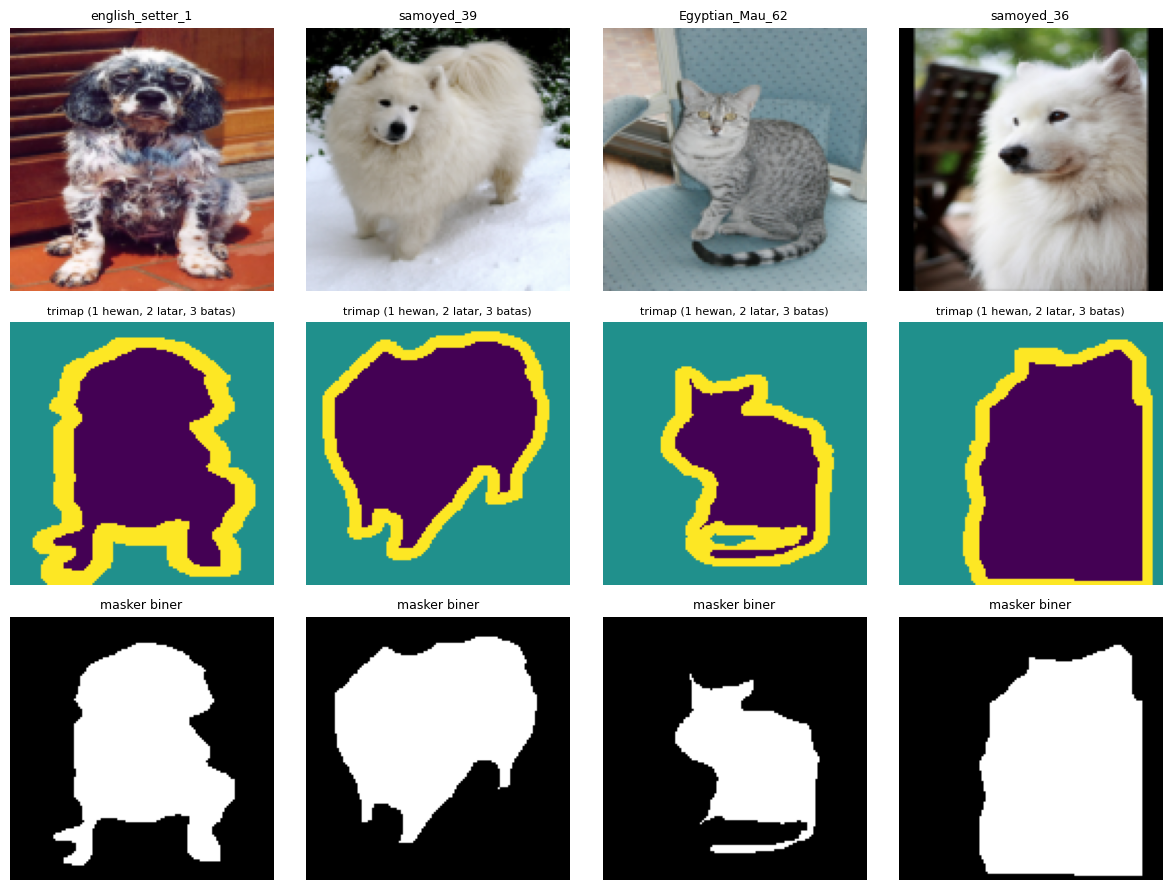

In [5]:
def denorm(x):
    return (x * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for k in range(4):
    x, y, v = ds_test[k]
    ax[0, k].imshow(denorm(x)); ax[0, k].set_title(ID_TEST[k], fontsize=9)
    ax[1, k].imshow(ds_test.tri[k], cmap="viridis", vmin=1, vmax=3); ax[1, k].set_title("trimap (1 hewan, 2 latar, 3 batas)", fontsize=8)
    ax[2, k].imshow(y[0], cmap="gray"); ax[2, k].set_title("masker biner", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_dl_contoh_data.png", dpi=120); plt.show()

#Tugas Kecil D1: Proporsi Piksel Data Uji & Piksel Batas

In [17]:
tri_test = ds_test.tri
print("Proporsi piksel data uji:")
print("  Hewan (1) : %.3f" % (tri_test == 1).float().mean().item())
print("  Latar (2) : %.3f" % (tri_test == 2).float().mean().item())
print("  Batas (3) : %.3f" % (tri_test == 3).float().mean().item())

Proporsi piksel data uji:
  Hewan (1) : 0.294
  Latar (2) : 0.580
  Batas (3) : 0.126


#Praktikum D2: Membangun dan Melatih U-Net dari Nol

1 Arsitektur U-Net kecil

In [6]:
class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=16):
        super().__init__()
        c = [base, base*2, base*4, base*8, base*16]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0])] +
                                  [DoubleConv(c[i], c[i+1]) for i in range(4)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(c[i+1], c[i], 2, stride=2) for i in reversed(range(4))])
        self.dec = nn.ModuleList([DoubleConv(c[i]*2, c[i]) for i in reversed(range(4))])
        self.head = nn.Conv2d(c[0], out_ch, 1)

    def forward(self, x):
        skips = []
        for i, blk in enumerate(self.enc):
            x = blk(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        x = skips.pop()
        for up, dec in zip(self.up, self.dec):
            x = up(x)
            x = dec(torch.cat([x, skips.pop()], dim=1))
        return self.head(x)

unet = UNet(base=CFG["BASE_CH"]).to(DEVICE)
print("Jumlah parameter U-Net: %.2f juta" % (sum(p.numel() for p in unet.parameters()) / 1e6))
print("Uji bentuk keluaran:", tuple(unet(torch.zeros(2, 3, CFG["IMG"], CFG["IMG"], device=DEVICE)).shape))

Jumlah parameter U-Net: 1.94 juta
Uji bentuk keluaran: (2, 1, 128, 128)


2 Loss BCE + Dice dengan masker valid, dan fungsi pelatihan umum

In [8]:
def bce_dice_loss(logit, y, valid, w_dice=1.0, eps=1.0):
    bce = F.binary_cross_entropy_with_logits(logit, y, reduction="none")
    bce = (bce * valid).sum() / valid.sum().clamp_min(1)
    p = torch.sigmoid(logit) * valid
    inter = (p * y * valid).sum(dim=(1, 2, 3))
    dice = 1 - (2 * inter + eps) / (p.sum(dim=(1, 2, 3)) + (y * valid).sum(dim=(1, 2, 3)) + eps)
    return bce + w_dice * dice.mean()

def latih(model, forward, epochs, lr, nama, param_groups=None):
    opt = torch.optim.AdamW(param_groups or model.parameters(), lr=lr, weight_decay=1e-4)
    riwayat = {"train": [], "test": []}
    t0 = time.time()
    for ep in range(epochs):
        model.train(); tot = 0
        for x, y, v in dl_train:
            x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
            loss = bce_dice_loss(forward(model, x), y, v)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(x)
        model.eval(); tot_te = 0
        with torch.no_grad():
            for x, y, v in dl_test:
                x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
                tot_te += bce_dice_loss(forward(model, x), y, v).item() * len(x)
        riwayat["train"].append(tot / len(ds_train))
        riwayat["test"].append(tot_te / len(ds_test))
        print(f"[{nama}] epoch {ep+1}/{epochs} loss latih {riwayat['train'][-1]:.4f} loss uji {riwayat['test'][-1]:.4f} ({time.time()-t0:.0f}s)")
    WAKTU[nama] = time.time() - t0
    return riwayat

fwd_unet = lambda m, x: m(x)
set_seed(42)
hist_unet = latih(unet, fwd_unet, CFG["EP_UNET"], 1e-3, "U-Net (dari nol)")

[U-Net (dari nol)] epoch 1/6 loss latih 0.7164 loss uji 0.6667 (77s)
[U-Net (dari nol)] epoch 2/6 loss latih 0.6324 loss uji 0.5663 (143s)
[U-Net (dari nol)] epoch 3/6 loss latih 0.5707 loss uji 0.5324 (191s)
[U-Net (dari nol)] epoch 4/6 loss latih 0.5409 loss uji 0.4916 (240s)
[U-Net (dari nol)] epoch 5/6 loss latih 0.5131 loss uji 0.5538 (291s)
[U-Net (dari nol)] epoch 6/6 loss latih 0.5079 loss uji 0.5975 (340s)


3 Kurva loss U-Net

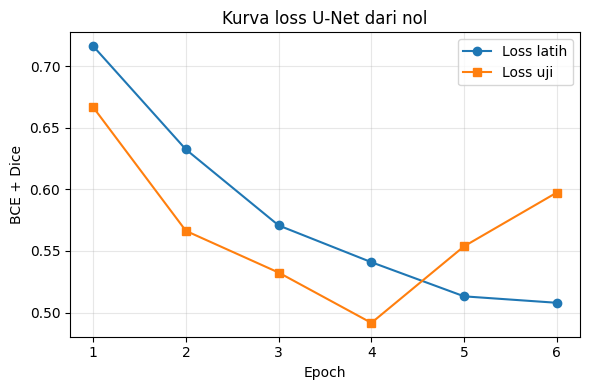

In [9]:
plt.figure(figsize=(6, 4))
ep = range(1, len(hist_unet["train"]) + 1)
plt.plot(ep, hist_unet["train"], "o-", label="Loss latih")
plt.plot(ep, hist_unet["test"], "s-", label="Loss uji")
plt.xlabel("Epoch"); plt.ylabel("BCE + Dice"); plt.title("Kurva loss U-Net dari nol"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d2_kurva_unet.png", dpi=120); plt.show()

#Tugas Kecil D2: Eksperimen Loss Tanpa Dice (w_dice = 0)

In [18]:
unet_bce = UNet(base=CFG["BASE_CH"]).to(DEVICE)

def fwd_unet_bce(m, x): return m(x)

set_seed(42)
hist_unet_bce = latih(unet_bce, fwd_unet_bce, CFG["EP_UNET"], 1e-3, "U-Net (Hanya BCE)")

hasil_bce = evaluasi(unet_bce, fwd_unet_bce)
print("U-Net (Hanya BCE):", ringkas(hasil_bce))
print("U-Net (BCE + Dice):", ringkas(HASIL["U-Net (dari nol)"]))

[U-Net (Hanya BCE)] epoch 1/6 loss latih 1.2327 loss uji 1.2296 (49s)
[U-Net (Hanya BCE)] epoch 2/6 loss latih 0.9574 loss uji 0.8173 (99s)
[U-Net (Hanya BCE)] epoch 3/6 loss latih 0.8343 loss uji 0.7538 (146s)
[U-Net (Hanya BCE)] epoch 4/6 loss latih 0.7695 loss uji 0.6908 (192s)
[U-Net (Hanya BCE)] epoch 5/6 loss latih 0.6970 loss uji 0.7777 (240s)
[U-Net (Hanya BCE)] epoch 6/6 loss latih 0.6560 loss uji 0.6906 (286s)
U-Net (Hanya BCE): {'IoU hewan': 0.6486, 'IoU latar': 0.7654, 'mIoU': 0.707, 'Dice': 0.7869, 'PixelAcc': 0.8363}
U-Net (BCE + Dice): {'IoU hewan': 0.6863, 'IoU latar': 0.7991, 'mIoU': 0.7427, 'Dice': 0.814, 'PixelAcc': 0.8604}


#Praktikum D3: Metrik Evaluasi Segmentasi

1 Fungsi metrik dan evaluasi

In [10]:
@torch.no_grad()
def evaluasi(model, forward, thr=0.5):
    model.eval()
    TP = FP = FN = TN = 0; iou_per_citra = []
    for x, y, v in dl_test:
        x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
        pred = (torch.sigmoid(forward(model, x)) > thr).float()
        tp = (pred * y * v).sum(dim=(1, 2, 3)); fp = (pred * (1 - y) * v).sum(dim=(1, 2, 3))
        fn = ((1 - pred) * y * v).sum(dim=(1, 2, 3)); tn = ((1 - pred) * (1 - y) * v).sum(dim=(1, 2, 3))
        TP += tp.sum().item(); FP += fp.sum().item(); FN += fn.sum().item(); TN += tn.sum().item()
        iou_per_citra += (tp / (tp + fp + fn).clamp_min(1)).tolist()
    iou_fg = TP / (TP + FP + FN); iou_bg = TN / (TN + FN + FP)
    return {"IoU hewan": iou_fg, "IoU latar": iou_bg, "mIoU": (iou_fg + iou_bg) / 2,
            "Dice": 2 * TP / (2 * TP + FP + FN), "PixelAcc": (TP + TN) / (TP + TN + FP + FN),
            "iou_per_citra": iou_per_citra}

def ringkas(m):
    return {k: round(v, 4) for k, v in m.items() if k != "iou_per_citra"}

HASIL = {}
HASIL["U-Net (dari nol)"] = evaluasi(unet, fwd_unet)
print(ringkas(HASIL["U-Net (dari nol)"]))

{'IoU hewan': 0.6863, 'IoU latar': 0.7991, 'mIoU': 0.7427, 'Dice': 0.814, 'PixelAcc': 0.8604}


2 Visualisasi prediksi U-Net

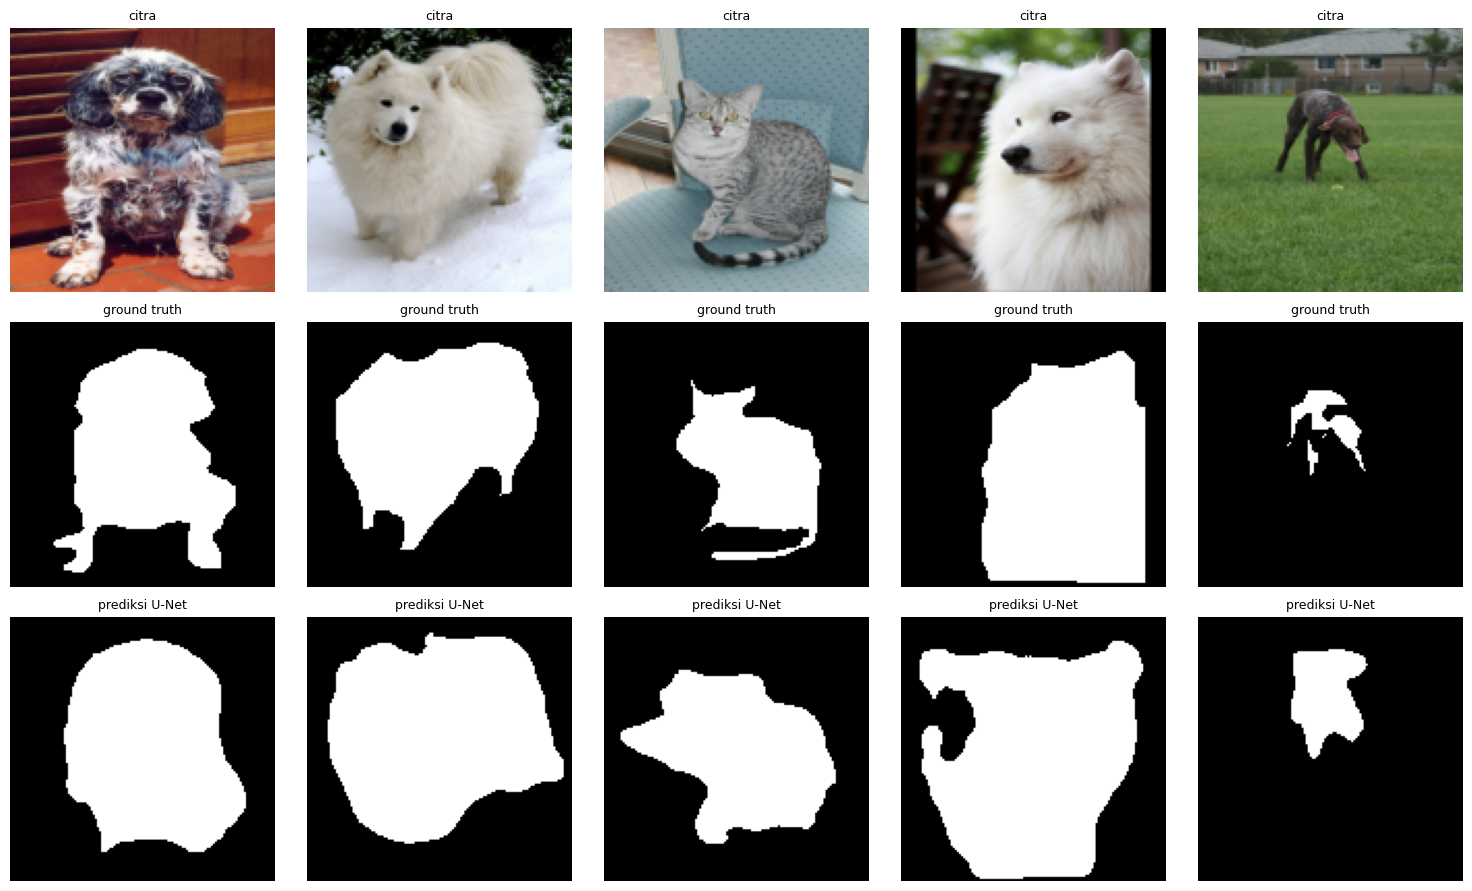

In [11]:
@torch.no_grad()
def prediksi(model, forward, idx):
    x = torch.stack([ds_test[i][0] for i in idx]).to(DEVICE)
    return (torch.sigmoid(forward(model, x)) > 0.5).float().cpu()

idx_vis = [0, 1, 2, 3, 4]
p_unet = prediksi(unet, fwd_unet, idx_vis)
fig, ax = plt.subplots(3, len(idx_vis), figsize=(3 * len(idx_vis), 9))
for j, i in enumerate(idx_vis):
    x, y, v = ds_test[i]
    ax[0, j].imshow(denorm(x)); ax[0, j].set_title("citra", fontsize=9)
    ax[1, j].imshow(y[0], cmap="gray"); ax[1, j].set_title("ground truth", fontsize=9)
    ax[2, j].imshow(p_unet[j, 0], cmap="gray"); ax[2, j].set_title("prediksi U-Net", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d3_prediksi_unet.png", dpi=120); plt.show()

#Tugas Kecil D3: Pengaruh Threshold Prediksi (0,3 dan 0,7)

In [19]:
for threshold in [0.3, 0.5, 0.7]:
    m = evaluasi(unet, fwd_unet, thr=threshold)
    print(f"Threshold = {threshold}:")
    print(f"  IoU Hewan : {m['IoU hewan']:.4f}")
    print(f"  Dice      : {m['Dice']:.4f}")
    print(f"  mIoU      : {m['mIoU']:.4f}")

Threshold = 0.3:
  IoU Hewan : 0.6434
  Dice      : 0.7830
  mIoU      : 0.6910
Threshold = 0.5:
  IoU Hewan : 0.6863
  Dice      : 0.8140
  mIoU      : 0.7427
Threshold = 0.7:
  IoU Hewan : 0.6990
  Dice      : 0.8228
  mIoU      : 0.7609


#Praktikum D4: Transfer Learning dengan DeepLabV3

1 Muat DeepLabV3 pra-latih dan ganti kepala klasifikasi

In [12]:
from torchvision.models.segmentation import deeplabv3_mobilenet_v3_large, DeepLabV3_MobileNet_V3_Large_Weights

set_seed(42)
dlv3 = deeplabv3_mobilenet_v3_large(weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT)
dlv3.classifier[4] = nn.Conv2d(256, 1, kernel_size=1) # 21 kelas VOC -> 1 kanal
dlv3.aux_classifier = None
dlv3 = dlv3.to(DEVICE)

fwd_dlv3 = lambda m, x: m(x)["out"]
print("Jumlah parameter DeepLabV3-MobileNetV3: %.2f juta" % (sum(p.numel() for p in dlv3.parameters()) / 1e6))

groups = [{"params": dlv3.backbone.parameters(), "lr": 1e-4}, # backbone: lr kecil
          {"params": dlv3.classifier.parameters(), "lr": 1e-3}] # kepala baru: lr besar

hist_dlv3 = latih(dlv3, fwd_dlv3, CFG["EP_DLV3"], 1e-3, "DeepLabV3-MobileNetV3 (pra-latih)", param_groups=groups)
HASIL["DeepLabV3-MobileNetV3 (pra-latih)"] = evaluasi(dlv3, fwd_dlv3)
print(ringkas(HASIL["DeepLabV3-MobileNetV3 (pra-latih)"]))

Downloading: "https://download.pytorch.org/models/deeplabv3_mobilenet_v3_large-fc3c493d.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_mobilenet_v3_large-fc3c493d.pth


100%|██████████| 42.3M/42.3M [00:00<00:00, 117MB/s]


Jumlah parameter DeepLabV3-MobileNetV3: 11.02 juta
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 1/2 loss latih 0.5867 loss uji 0.4916 (51s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 2/2 loss latih 0.3292 loss uji 0.3206 (100s)
{'IoU hewan': 0.8443, 'IoU latar': 0.9111, 'mIoU': 0.8777, 'Dice': 0.9156, 'PixelAcc': 0.94}


#Tugas Kecil D4: Pembekuan Backbone DeepLabV3

In [20]:
dlv3_frozen = deeplabv3_mobilenet_v3_large(weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT)
dlv3_frozen.classifier[4] = nn.Conv2d(256, 1, kernel_size=1)
dlv3_frozen.aux_classifier = None

for param in dlv3_frozen.backbone.parameters():
    param.requires_grad = False

dlv3_frozen = dlv3_frozen.to(DEVICE)

hist_frozen = latih(dlv3_frozen, fwd_dlv3, CFG["EP_DLV3"], 1e-3, "DeepLabV3 (Frozen Backbone)")
hasil_frozen = evaluasi(dlv3_frozen, fwd_dlv3)

print("Hasil DeepLabV3 (Frozen):", ringkas(hasil_frozen))

[DeepLabV3 (Frozen Backbone)] epoch 1/2 loss latih 0.5952 loss uji 0.4635 (34s)
[DeepLabV3 (Frozen Backbone)] epoch 2/2 loss latih 0.3959 loss uji 0.3136 (61s)
Hasil DeepLabV3 (Frozen): {'IoU hewan': 0.8379, 'IoU latar': 0.9093, 'mIoU': 0.8736, 'Dice': 0.9118, 'PixelAcc': 0.9383}


#Praktikum D5: Fine-Tuning SegFormer-B0

1 Muat SegFormer-B0 dan latih

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Jumlah parameter SegFormer-B0: 3.71 juta


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[SegFormer-B0 (pra-latih)] epoch 1/3 loss latih 0.7582 loss uji 0.5295 (35s)
[SegFormer-B0 (pra-latih)] epoch 2/3 loss latih 0.4253 loss uji 0.4133 (71s)
[SegFormer-B0 (pra-latih)] epoch 3/3 loss latih 0.3069 loss uji 0.2994 (104s)
{'IoU hewan': 0.8712, 'IoU latar': 0.9316, 'mIoU': 0.9014, 'Dice': 0.9312, 'PixelAcc': 0.9532}


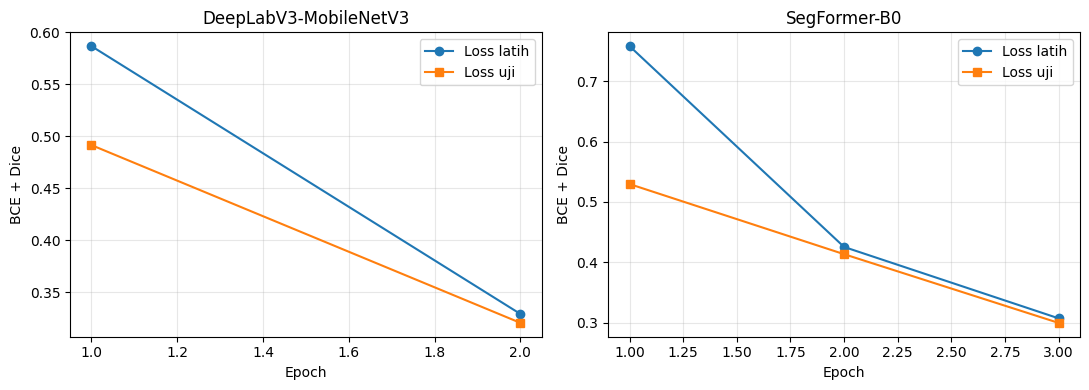

In [13]:
import transformers
from transformers import SegformerForSemanticSegmentation
transformers.logging.set_verbosity_error()

set_seed(42)
segf = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b0", num_labels=1).to(DEVICE)
print("Jumlah parameter SegFormer-B0: %.2f juta" % (sum(p.numel() for p in segf.parameters()) / 1e6))

def fwd_segf(m, x):
    logit = m(pixel_values=x).logits
    return F.interpolate(logit, size=x.shape[-2:], mode="bilinear", align_corners=False)

hist_segf = latih(segf, fwd_segf, CFG["EP_SEGF"], 3e-4, "SegFormer-B0 (pra-latih)")
HASIL["SegFormer-B0 (pra-latih)"] = evaluasi(segf, fwd_segf)
print(ringkas(HASIL["SegFormer-B0 (pra-latih)"]))


fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (nama, h) in zip(ax, [("DeepLabV3-MobileNetV3", hist_dlv3), ("SegFormer-B0", hist_segf)]):
    ep = range(1, len(h["train"]) + 1)
    a.plot(ep, h["train"], "o-", label="Loss latih"); a.plot(ep, h["test"], "s-", label="Loss uji")
    a.set_title(nama); a.set_xlabel("Epoch"); a.set_ylabel("BCE + Dice"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d5_kurva_pralatih.png", dpi=120); plt.show()

#Tugas Kecil D5: Penggunaan SegFormer-B1

In [21]:
segf_b1 = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b1", num_labels=1).to(DEVICE)

print("Jumlah parameter SegFormer-B1: %.2f juta" %
      (sum(p.numel() for p in segf_b1.parameters()) / 1e6))

hist_segf_b1 = latih(segf_b1, fwd_segf, CFG["EP_SEGF"], 3e-4, "SegFormer-B1 (pra-latih)")
hasil_segf_b1 = evaluasi(segf_b1, fwd_segf)

print("Hasil SegFormer-B1:", ringkas(hasil_segf_b1))

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 54.7MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Jumlah parameter SegFormer-B1: 13.68 juta


model.safetensors: reconstructing file:   0%|          |  0.00B / 54.7MB            

model.safetensors: downloading bytes:           |  0.00B            

[SegFormer-B1 (pra-latih)] epoch 1/3 loss latih 0.6984 loss uji 0.5847 (65s)
[SegFormer-B1 (pra-latih)] epoch 2/3 loss latih 0.4100 loss uji 0.3693 (120s)
[SegFormer-B1 (pra-latih)] epoch 3/3 loss latih 0.2996 loss uji 0.2727 (179s)
Hasil SegFormer-B1: {'IoU hewan': 0.8781, 'IoU latar': 0.9386, 'mIoU': 0.9084, 'Dice': 0.9351, 'PixelAcc': 0.9574}


#Praktikum D6: Perbandingan Model dan Analisis Kesalahan

1 Tabel perbandingan

In [14]:
import pandas as pd

param = {"U-Net (dari nol)": unet, "DeepLabV3-MobileNetV3 (pra-latih)": dlv3, "SegFormer-B0 (pra-latih)": segf}
tabel = pd.DataFrame([{"Model": k, **ringkas(v), "Parameter (juta)": round(sum(p.numel() for p in param[k].parameters()) / 1e6, 2), "Waktu latih (s)": round(WAKTU[k], 1)} for k, v in HASIL.items()])
print(tabel.to_string(index=False))
tabel.to_csv(f"{FIG_DIR}/js05_tabel_hasil.csv", index=False)

with open(f"{FIG_DIR}/js05_hasil.json", "w") as f:
    json.dump({"perangkat": DEVICE, "mode": "CEPAT" if CEPAT else "PENUH", "cfg": CFG, "hasil": {k: ringkas(v) for k, v in HASIL.items()}, "waktu_detik": WAKTU}, f, indent=2)

                            Model  IoU hewan  IoU latar   mIoU   Dice  PixelAcc  Parameter (juta)  Waktu latih (s)
                 U-Net (dari nol)     0.6863     0.7991 0.7427 0.8140    0.8604              1.94            340.0
DeepLabV3-MobileNetV3 (pra-latih)     0.8443     0.9111 0.8777 0.9156    0.9400             11.02            100.4
         SegFormer-B0 (pra-latih)     0.8712     0.9316 0.9014 0.9312    0.9532              3.71            103.7


2 Contoh prediksi ketiga model

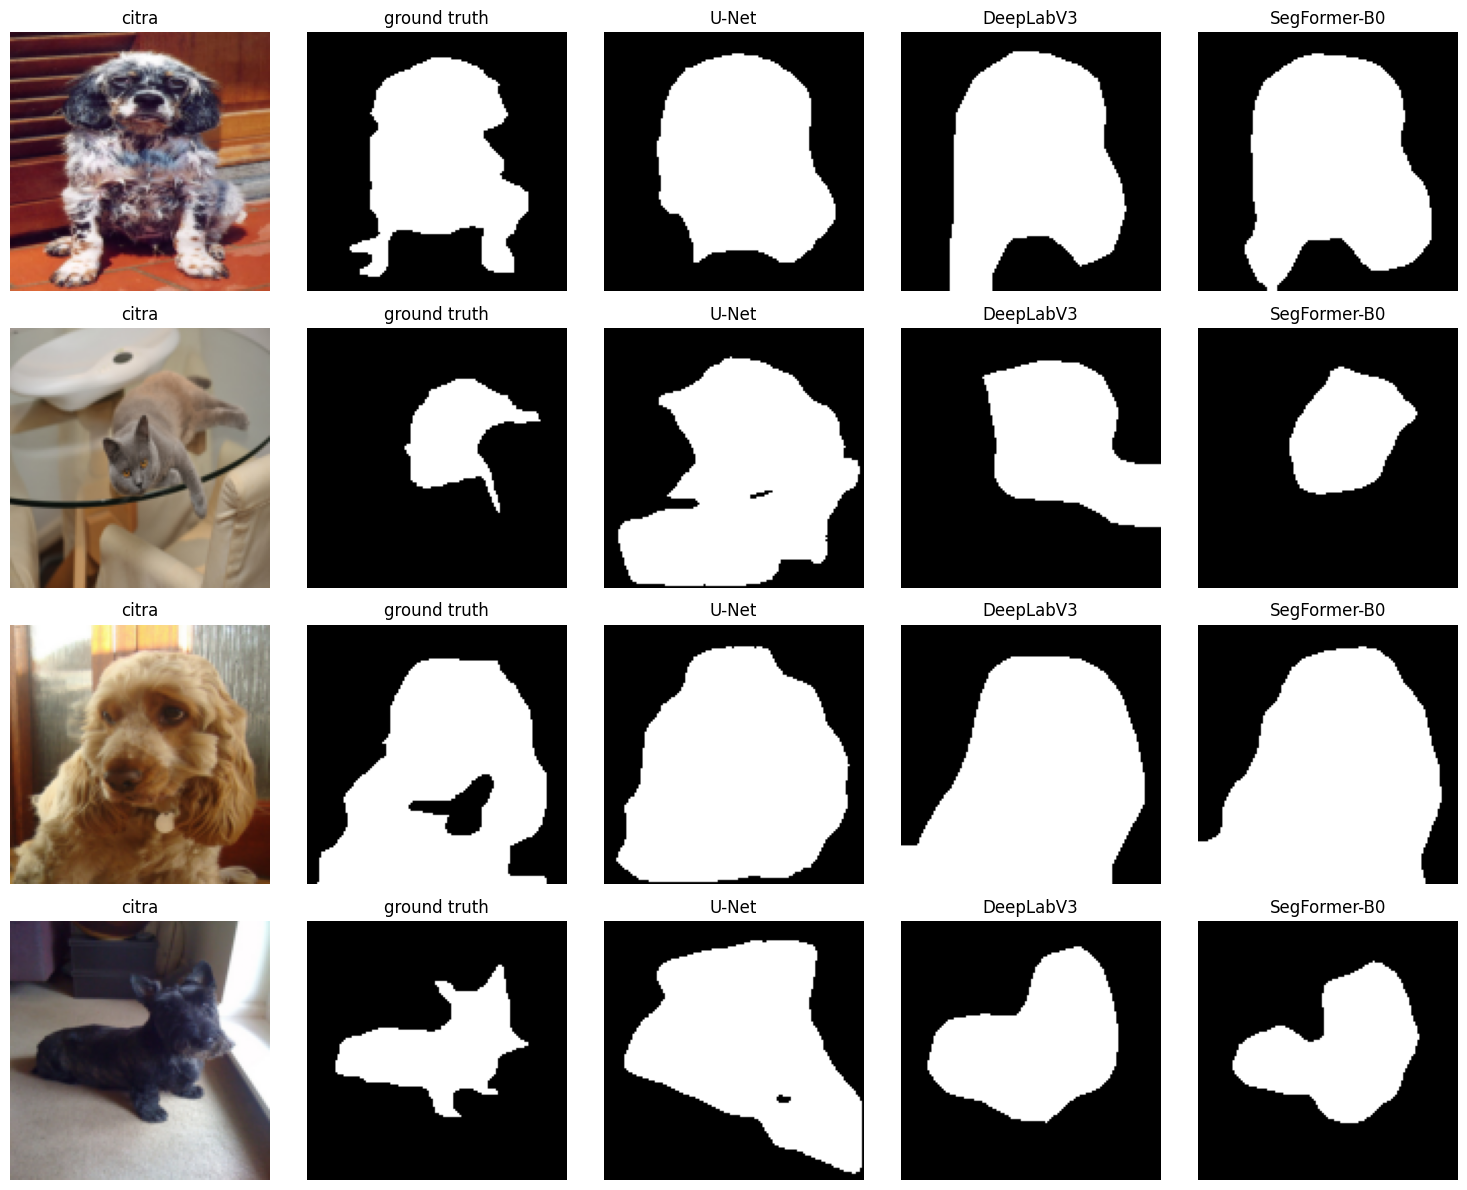

In [15]:
model_fwd = [("U-Net", unet, fwd_unet), ("DeepLabV3", dlv3, fwd_dlv3), ("SegFormer-B0", segf, fwd_segf)]
idx_vis = [0, 5, 10, 15]

fig, ax = plt.subplots(len(idx_vis), 5, figsize=(15, 3 * len(idx_vis)))
preds = {n: prediksi(m, f, idx_vis) for n, m, f in model_fwd}

for r, i in enumerate(idx_vis):
    x, y, v = ds_test[i]
    ax[r, 0].imshow(denorm(x)); ax[r, 0].set_title("citra")
    ax[r, 1].imshow(y[0], cmap="gray"); ax[r, 1].set_title("ground truth")
    for c, (n, _, _) in enumerate(model_fwd):
        ax[r, c + 2].imshow(preds[n][r, 0], cmap="gray")
        ax[r, c + 2].set_title(n)

for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_perbandingan.png", dpi=110); plt.show()

3 Analisis kesalahan: distribusi IoU per citra dan kasus terburuk

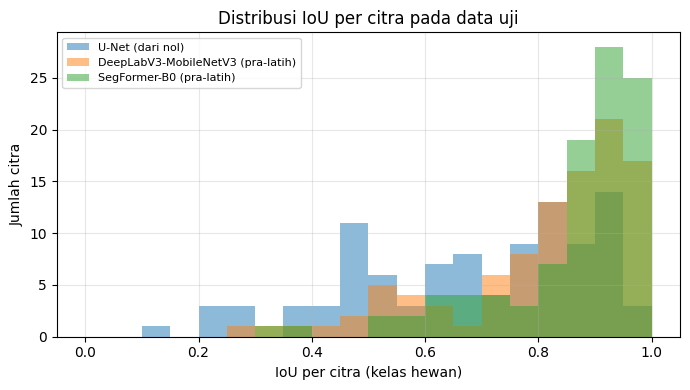

/tmp/ipykernel_1299/3334517196.py:20: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  peta[(p == 1) & (g == 1) & (val == 1).numpy()] = [0, .8, 0]
/tmp/ipykernel_1299/3334517196.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  peta[(p == 1) & (g == 0) & (val == 1).numpy()] = [1, 0, 0]
/tmp/ipykernel_1299/3334517196.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  peta[(p == 0) & (g == 1) & (val == 1).numpy()] = [0, .3, 1]


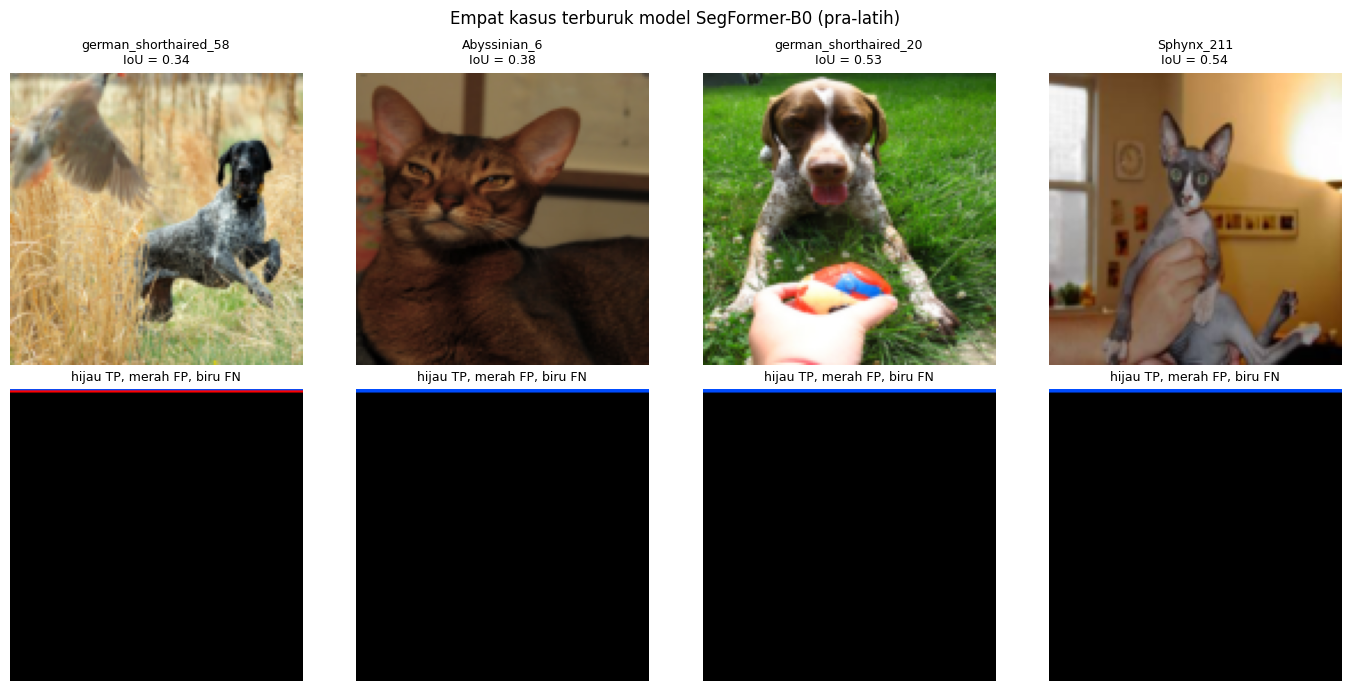

Model terbaik: SegFormer-B0 (pra-latih) | IoU terendah: [0.339, 0.376, 0.533, 0.536]


In [16]:
plt.figure(figsize=(7, 4))
for n, m in HASIL.items():
    plt.hist(m["iou_per_citra"], bins=20, range=(0, 1), alpha=.5, label=n)
plt.xlabel("IoU per citra (kelas hewan)"); plt.ylabel("Jumlah citra"); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.title("Distribusi IoU per citra pada data uji")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_histogram_iou.png", dpi=120); plt.show()

terbaik = max(HASIL, key=lambda k: HASIL[k]["mIoU"])
mdl, fw = {"U-Net (dari nol)": (unet, fwd_unet),
           "DeepLabV3-MobileNetV3 (pra-latih)": (dlv3, fwd_dlv3),
           "SegFormer-B0 (pra-latih)": (segf, fwd_segf)}[terbaik]

iou = np.array(HASIL[terbaik]["iou_per_citra"]); buruk = np.argsort(iou)[:4].tolist()
ppb = prediksi(mdl, fw, buruk)

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j, i in enumerate(buruk):
    x, y, v = ds_test[i]; p = ppb[j, 0]; g = y[0]; val = v[0]
    peta = np.zeros((*g.shape, 3))
    peta[(p == 1) & (g == 1) & (val == 1).numpy()] = [0, .8, 0]
    peta[(p == 1) & (g == 0) & (val == 1).numpy()] = [1, 0, 0]
    peta[(p == 0) & (g == 1) & (val == 1).numpy()] = [0, .3, 1]
    ax[0, j].imshow(denorm(x)); ax[0, j].set_title(f"{ID_TEST[i]}\nIoU = {iou[i]:.2f}", fontsize=9)
    ax[1, j].imshow(peta); ax[1, j].set_title("hijau TP, merah FP, biru FN", fontsize=9)

for a in ax.ravel(): a.axis("off")
plt.suptitle(f"Empat kasus terburuk model {terbaik}")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_kasus_terburuk.png", dpi=110); plt.show()
print("Model terbaik:", terbaik, "| IoU terendah:", np.round(iou[buruk], 3).tolist())

#Tugas Kecil D6: Analisis Kesalahan & Eksperimen Perbaikan

In [24]:
class PetSegDatasetAug(PetSegDataset):
    def __getitem__(self, i):
        x = self.img[i].float() / 255.0
        tri = self.tri[i]
        y = (tri == 1).float().unsqueeze(0)
        valid = (tri != 3).float().unsqueeze(0)

        if self.augment:
            if random.random() < 0.5:
                x, y, valid = x.flip(-1), y.flip(-1), valid.flip(-1)

            if random.random() < 0.5:
                factor = random.uniform(0.8, 1.2)
                x = torch.clamp(x * factor, 0.0, 1.0)

        return (x - MEAN) / STD, y, valid

ds_train_aug = PetSegDatasetAug(ID_TRAIN, CFG["IMG"], augment=True)
dl_train_aug = torch.utils.data.DataLoader(ds_train_aug, batch_size=CFG["BATCH"], shuffle=True)